# A transport junction by hand — every matrix, every file

The worked example of `docs/engines/transport.md` § 1.3, as cells to run and change.

**What this is:** the same steps and equations molbuilder's five transport rungs run — the lead's H and S, Lopez Sancho, the self-energy, the seed, the device's self-consistent cycle, a bias point, the transmission, the current — on a **model** junction small enough to print every matrix: one orbital per site, four sites, an orthogonal basis (S = 1).

**What it is not:** SIESTA. It runs no SIESTA and reads no SIESTA file. SIESTA's Hamiltonian is Kohn–Sham DFT in atomic orbitals (S a matrix); here one number, `U`, stands in for how a site's level follows its charge. TranSIESTA integrates the equilibrium density on a complex contour with poles; here, on the real axis. § 1.3 has the full table of what carries over and what does not.

Change any number in the next cell and run the notebook again.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

# THE MODEL -- energies in eV; one orbital per site; an orthogonal basis (S = 1)
eps_lead, t_lead = 0.0, -2.0          # the gold: on-site, hopping -> band -4 ... +4
eps_mol, t_mol, t_c = 1.0, -1.5, -1.0 # the molecule: on-site, internal, to each lead
U, n_ref = 1.0, 1.0                   # a site's level rises U per electron it gains
kT, eta = 0.025852, 1e-3              # 300 K; the broadening (TS/TBT.Elecs.Eta, 1 meV)
f = lambda E, mu: 1.0 / (1.0 + np.exp((E - mu) / kT))

## Steps 2–3 · a lead's run → its `.TSHS`

The lead is periodic along z, one site a cell: its Hamiltonian is the cell's own block **H₀₀** and its coupling to the next cell **H₀₁**, with the overlap beside each, and its Fermi level. That is all a lead hands on — no self-energy is in the file.

In [2]:
H00, H01, S00, S01, E_F = eps_lead, t_lead, 1.0, 0.0, 0.0
print("the lead's .TSHS holds:  H00 =", H00, " H01 =", H01, " S00 =", S00, " S01 =", S01, " E_F =", E_F)

the lead's .TSHS holds:  H00 = 0.0  H01 = -2.0  S00 = 1.0  S01 = 0.0  E_F = 0.0


## The self-energy, from the `.TSHS` — Lopez Sancho

At each energy, the surface Green's function of the half-infinite lead is summed by doubling: each iteration folds twice as many cells in, until the coupling left to fold is zero (TranSIESTA's `m_ts_electrode.F90`). Under a bias the lead's E_F is placed at its chemical potential μ first: `H00 − (E_F − μ)·S00`.

In [3]:
def surface_g(E, mu, show=False):
    z, h00 = E + 1j * eta, H00 - (E_F - mu) * S00
    a, b = H01 - z * S01, H01 - z * S01
    es = e = z * S00 - h00
    it = 0
    while abs(a) > 1e-12:
        g = 1.0 / e
        es, e = es - a * g * b, e - a * g * b - b * g * a
        a, b = a * g * a, b * g * b
        it += 1
        if show:
            print(f"  iteration {it:2d}: coupling still to fold {abs(a):.2e}")
    return 1.0 / es

def sigma(E, mu):            # the self-energy on the electrode site: H10 g H01
    return H01 * surface_g(E, mu) * H01

print("g_s(0) =", surface_g(0.0, 0.0, show=True))
for E in [-3.0, -0.5, 0.0, 1.0, 2.5]:
    s = sigma(E, 0.0)
    print(f"E = {E:+.1f}:  Sigma = {s:.4f}   Gamma = i(Sigma - Sigma*) = {(1j*(s - s.conjugate())).real:.4f}")

  iteration  1: coupling still to fold 4.00e+03
  iteration  2: coupling still to fold 2.00e+03
  iteration  3: coupling still to fold 1.00e+03
  iteration  4: coupling still to fold 5.00e+02
  iteration  5: coupling still to fold 2.50e+02
  iteration  6: coupling still to fold 1.25e+02
  iteration  7: coupling still to fold 6.25e+01
  iteration  8: coupling still to fold 3.12e+01
  iteration  9: coupling still to fold 1.56e+01
  iteration 10: coupling still to fold 7.73e+00
  iteration 11: coupling still to fold 3.74e+00
  iteration 12: coupling still to fold 1.65e+00
  iteration 13: coupling still to fold 5.25e-01
  iteration 14: coupling still to fold 6.66e-02
  iteration 15: coupling still to fold 1.11e-03
  iteration 16: coupling still to fold 3.07e-07
  iteration 17: coupling still to fold 2.35e-14
g_s(0) = -0.49987501584924543j
E = -3.0:  Sigma = -1.4994-1.3224j   Gamma = i(Sigma - Sigma*) = 2.6448
E = -0.5:  Sigma = -0.2499-1.9838j   Gamma = i(Sigma - Sigma*) = 3.9676
E = +0.0:

## Step 1 · the seed → `.DM`

The whole four-site cell as a periodic crystal along z (site 3 couples to site 0 of the next cell), filled to E_F. Its density matrix ρ₀: the diagonal is each site's electrons (both spins), off the diagonal the bond orders. It is only where the device starts.

In [4]:
def H_of(n, V):               # STEP 4's Hamiltonian H[rho]; at V = 0 it is the seed's cell too
    ramp = np.array([V / 2, V / 6, -V / 6, -V / 2])        # the bias, as a ramp
    H = np.diag([eps_lead, eps_mol + U * (n[0] - n_ref),
                 eps_mol + U * (n[1] - n_ref), eps_lead] + ramp)
    for i, j, t in [(0, 1, t_c), (1, 2, t_mol), (2, 3, t_c)]:
        H[i, j] = H[j, i] = t
    return H

rho_seed = np.zeros((4, 4), complex)
for k in np.linspace(-np.pi, np.pi, 200, endpoint=False):
    Hk = H_of([n_ref, n_ref], 0.0).astype(complex)
    Hk[3, 0] += t_lead * np.exp(1j * k); Hk[0, 3] += t_lead * np.exp(-1j * k)
    w, v = np.linalg.eigh(Hk)
    rho_seed += (v * 2 * f(w, E_F)) @ v.conj().T / 200
rho_seed = rho_seed.real
print("seed .DM =\n", rho_seed)

seed .DM =
 [[ 1.0341  0.3374  0.0843 -0.0437]
 [ 0.3374  0.9146  0.852   0.0843]
 [ 0.0843  0.852   0.9146  0.3374]
 [-0.0437  0.0843  0.3374  1.0341]]


## Step 4 · the device at 0 V → `.TSDE` and `.TS.HSX`

Open now: the leads attach to sites 0 and 3 through their self-energies, computed once at every energy of the integral — what TranSIESTA keeps in `tsgf/<label>.v0.TSGFL` / `.TSGFR` — and read back every iteration. One iteration:

1. **H[ρ]**: each molecule site's level is 1.0 + U·(n − 1); the electrode blocks keep the lead's own (`TS.Elecs.Bulk true`).
2. **G(E)** = [(E + iη)·S − H − Σ_L − Σ_R]⁻¹ at every energy.
3. **ρ** = (2/2π) ∫ [G Γ_L G† f(E − μ_L) + G Γ_R G† f(E − μ_R)] dE.
4. **mix** new with old; stop when it no longer changes.

In [5]:
E = np.arange(-6.0, 6.0, 0.0005)

def lead_files(V):           # what tsgf/<label>.v<V>.TSGFL / .TSGFR hold
    return (np.array([sigma(e, +V / 2) for e in E]),
            np.array([sigma(e, -V / 2) for e in E]))

def G_of(H, SL, SR, z):
    A = np.zeros((len(z), 4, 4), complex); A[:] = -H
    A[:, range(4), range(4)] += z[:, None]
    A[:, 0, 0] -= SL; A[:, 3, 3] -= SR
    return np.linalg.inv(A)

def density(H, V, SL, SR):
    G = G_of(H, SL, SR, E + 1j * eta)
    gL, gR = (1j * (SL - SL.conj())).real, (1j * (SR - SR.conj())).real
    cL, cR = G[:, :, 0], G[:, :, 3]
    rho = (np.einsum('ei,ej,e->ij', cL, cL.conj(), gL * f(E, V / 2))
           + np.einsum('ei,ej,e->ij', cR, cR.conj(), gR * f(E, -V / 2)))
    return (2 * rho * (E[1] - E[0]) / (2 * np.pi)).real

def scf(V, n, leads, mix=0.5, tol=1e-4):
    for it in range(1, 100):
        rho = density(H_of(n, V), V, *leads)
        n_out = np.diag(rho)[1:3]
        print(f"  iteration {it}: molecule in {n}  out {n_out}")
        if abs(n_out - n).max() < tol:
            return n_out, H_of(n_out, V), rho
        n = (1 - mix) * n + mix * n_out

print("device at 0 V, from the seed:")
n0, H0, rho0 = scf(0.0, np.diag(rho_seed)[1:3], lead_files(0.0))
print("H(0 V) -> .TS.HSX =\n", H0)
print("rho(0 V) -> .TSDE =\n", rho0)
print("molecule-block levels:", np.linalg.eigvalsh(H0[1:3, 1:3]))

device at 0 V, from the seed:


  iteration 1: molecule in [0.9146 0.9146]  out [0.836 0.836]
  iteration 2: molecule in [0.8753 0.8753]  out [0.8478 0.8478]
  iteration 3: molecule in [0.8615 0.8615]  out [0.8517 0.8517]
  iteration 4: molecule in [0.8566 0.8566]  out [0.8531 0.8531]
  iteration 5: molecule in [0.8549 0.8549]  out [0.8536 0.8536]
  iteration 6: molecule in [0.8542 0.8542]  out [0.8538 0.8538]


  iteration 7: molecule in [0.854 0.854]  out [0.8538 0.8538]
  iteration 8: molecule in [0.8539 0.8539]  out [0.8538 0.8538]
H(0 V) -> .TS.HSX =
 [[ 0.     -1.      0.      0.    ]
 [-1.      0.8538 -1.5     0.    ]
 [ 0.     -1.5     0.8538 -1.    ]
 [ 0.      0.     -1.      0.    ]]
rho(0 V) -> .TSDE =
 [[ 0.9951  0.4176  0.1347 -0.0887]
 [ 0.4176  0.8538  0.7746  0.1347]
 [ 0.1347  0.7746  0.8538  0.4176]
 [-0.0887  0.1347  0.4176  0.9951]]
molecule-block levels: [-0.6462  2.3538]


## Step 4 · a bias point, 0.4 V → its own `.TSDE` and `.TS.HSX`

The left lead filled to μ_L = +0.2 eV, the right to μ_R = −0.2 eV, the potential falling across the device as a ramp. The leads' self-energies again at the shifted μ — the 0.4 V `tsgf/` pair — and the cycle started **from the 0 V density**, as the manual advises; compare with starting from the seed.

In [6]:
leads04 = lead_files(0.4)
print("device at 0.4 V, from the 0 V .TSDE:")
n4, H4, rho4 = scf(0.4, n0, leads04)
print("device at 0.4 V, from the seed instead:")
_ = scf(0.4, np.diag(rho_seed)[1:3], leads04)
print("H(0.4 V) -> v0.4/.TS.HSX =\n", H4)
print("rho(0.4 V) -> v0.4/.TSDE =\n", rho4)

device at 0.4 V, from the 0 V .TSDE:
  iteration 1: molecule in [0.8538 0.8538]  out [0.7976 0.8928]
  iteration 2: molecule in [0.8257 0.8733]  out [0.8115 0.8826]
  iteration 3: molecule in [0.8186 0.878 ]  out [0.815  0.8801]
  iteration 4: molecule in [0.8168 0.879 ]  out [0.8158 0.8795]
  iteration 5: molecule in [0.8163 0.8793]  out [0.8161 0.8794]


  iteration 6: molecule in [0.8162 0.8793]  out [0.8161 0.8793]
device at 0.4 V, from the seed instead:
  iteration 1: molecule in [0.9146 0.9146]  out [0.7794 0.8726]
  iteration 2: molecule in [0.847  0.8936]  out [0.8052 0.8763]
  iteration 3: molecule in [0.8261 0.885 ]  out [0.8128 0.878 ]
  iteration 4: molecule in [0.8194 0.8815]  out [0.8151 0.8788]
  iteration 5: molecule in [0.8172 0.8801]  out [0.8158 0.8791]


  iteration 6: molecule in [0.8165 0.8796]  out [0.816  0.8793]
  iteration 7: molecule in [0.8163 0.8794]  out [0.8161 0.8793]
  iteration 8: molecule in [0.8162 0.8794]  out [0.8161 0.8793]
H(0.4 V) -> v0.4/.TS.HSX =
 [[ 0.2    -1.      0.      0.    ]
 [-1.      0.8828 -1.5     0.    ]
 [ 0.     -1.5     0.8127 -1.    ]
 [ 0.      0.     -1.     -0.2   ]]
rho(0.4 V) -> v0.4/.TSDE =
 [[ 0.9756  0.3978  0.1129 -0.0842]
 [ 0.3978  0.8161  0.7673  0.1539]
 [ 0.1129  0.7673  0.8793  0.4361]
 [-0.0842  0.1539  0.4361  1.0173]]


## Step 5 · the transmission → `.TBT.nc`

tbtrans runs no cycle: it reads a point's H and both leads' `.TSHS`, rebuilds the self-energies at its own energies, and at each energy computes **T(E) = Tr[Γ_L G Γ_R G†]**. Every energy is independent: the 400 energies of a −2…2 window, computed again inside a −3…3 window, come out the same.

400 energies in -2..2, 600 in -3..3; the shared 400 agree to 1.7175150190951172e-13
resonances in -3..3: [-0.645, 2.635] -- the -2..2 window sees only the first


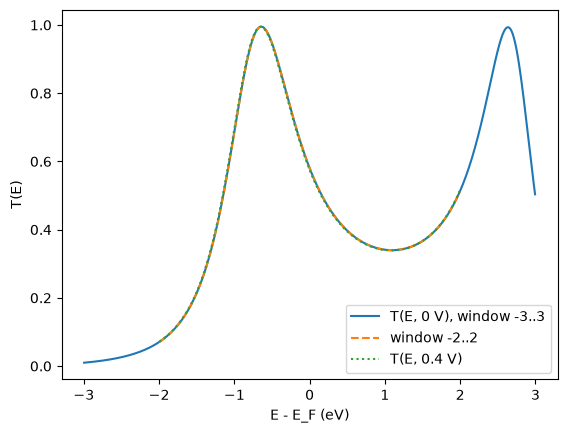

In [7]:
def T(Es, H, V):
    SL = np.array([sigma(e, +V / 2) for e in Es]); SR = np.array([sigma(e, -V / 2) for e in Es])
    G = G_of(H, SL, SR, Es + 1j * eta)
    gL, gR = (1j * (SL - SL.conj())).real, (1j * (SR - SR.conj())).real
    return gL * gR * np.abs(G[:, 0, 3]) ** 2

mid = lambda lo, hi, d=0.01: lo + d * (np.arange(round((hi - lo) / d)) + 0.5)   # the mid-rule grid
A, B = mid(-2, 2), mid(-3, 3)
TA, TB = T(A, H0, 0.0), T(B, H0, 0.0)
print(len(A), "energies in -2..2,", len(B), "in -3..3; the shared 400 agree to", abs(TB[100:500] - TA).max())
peaks = [round(float(B[i]), 3) for i in range(1, len(B) - 1) if TB[i] > TB[i-1] and TB[i] > TB[i+1]]
print("resonances in -3..3:", peaks, "-- the -2..2 window sees only the first")

import matplotlib.pyplot as plt
plt.plot(B, TB, label="T(E, 0 V), window -3..3")
plt.plot(A, TA, "--", label="window -2..2")
plt.plot(A, T(A, H4, 0.4), ":", label="T(E, 0.4 V)")
plt.xlabel("E - E_F (eV)"); plt.ylabel("T(E)"); plt.legend(); plt.show()

## The conductance and the current — the record

G = G₀·T(E_F); I(V) is T integrated over the bias window with both leads' Fermi functions — from T(E, 0) under the **low-bias approximation** (the record's own sum), or from T(E, V) at a **self-consistent** point.

In [8]:
G0 = 7.748091729e-5                                  # 2e^2/h, in siemens
I = lambda Es, Ts, V: G0 * np.sum(Ts * (f(Es, V / 2) - f(Es, -V / 2))) * (Es[1] - Es[0])
print(f"G = {T(np.array([0.0]), H0, 0.0)[0]:.4f} G0")
print(f"I(0.4 V): low-bias {I(A, TA, 0.4):.4e} A; self-consistent {I(A, T(A, H4, 0.4), 0.4):.4e} A")

G = 0.5804 G0
I(0.4 V): low-bias 1.8219e-05 A; self-consistent 1.8068e-05 A


# The same steps, run by SIESTA — the hydrogen chain

`docs/engines/transport.md` § 1.3, second half: the smallest junction molbuilder's real-engine test runs — 22 hydrogen atoms 1 Å apart (9 the left block, 4 the bridge, 9 the right), one s orbital each — run through the ordinary road at 0 V and 0.2 V. Its files are read here with `sisl`, step by step. `B` is the transport calculation's folder: as this notebook sits in the projects tree's `notebooks/`, the run made on 2026-10-22 is `../claude-transport-by-hand/transport/T`; point it at any transport calculation of your own.

In [9]:
import sisl, json
from pathlib import Path
B = Path("../claude-transport-by-hand/transport/T")

def block(M, isc, overlap=False):
    """One real-space block of a matrix: the cell's own (isc 0,0,0) or its
    coupling to the next cell along z (0,0,1)."""
    no, i = M.no, M.geometry.lattice.sc_index(isc)
    csr = M.tocsr(M.S_idx) if overlap else M.tocsr(0)
    return csr[:, i*no:(i+1)*no].toarray()

lead = sisl.get_sile(B / "02_electrode_L/run-0/T_L-electrode.TSHS")
HL = lead.read_hamiltonian()
print("the lead's .TSHS:", HL.geometry.na, "atoms,", HL.no, "orbitals; E_F =", round(lead.read_fermi_level(), 4), "eV")
print("H00 (eV) =\n", block(HL, [0, 0, 0]))
print("H01 (eV) =\n", block(HL, [0, 0, 1]))
print("S00 =\n", block(HL, [0, 0, 0], overlap=True))

the lead's .TSHS: 9 atoms, 9 orbitals; E_F = -6.0169 eV
H00 (eV) =
 [[-4.9992 -5.7262 -2.5951 -0.7217 -0.0955 -0.0032 -0.      0.      0.    ]
 [-5.7262 -4.9992 -5.7262 -2.5951 -0.7217 -0.0955 -0.0032 -0.      0.    ]
 [-2.5951 -5.7262 -4.9992 -5.7262 -2.5951 -0.7217 -0.0955 -0.0032 -0.    ]
 [-0.7217 -2.5951 -5.7262 -4.9992 -5.7262 -2.5951 -0.7217 -0.0955 -0.0032]
 [-0.0955 -0.7217 -2.5951 -5.7262 -4.9992 -5.7262 -2.5951 -0.7217 -0.0955]
 [-0.0032 -0.0955 -0.7217 -2.5951 -5.7262 -4.9992 -5.7262 -2.5951 -0.7217]
 [-0.     -0.0032 -0.0955 -0.7217 -2.5951 -5.7262 -4.9992 -5.7262 -2.5951]
 [ 0.     -0.     -0.0032 -0.0955 -0.7217 -2.5951 -5.7262 -4.9992 -5.7262]
 [ 0.      0.     -0.     -0.0032 -0.0955 -0.7217 -2.5951 -5.7262 -4.9992]]
H01 (eV) =
 [[ 0.      0.      0.      0.      0.      0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.      0.      0.      0.      0.      0.    ]
 [-0.      0.      

In [10]:
# what each device point took, and what it started from -- molbuilder's provenance notes
for f in ["04_device/run-0/.gathered-from", "04_device/run-0/v0.2/.continued-from",
          "05_transmission/run-0/v0.2/.gathered-from"]:
    print(f, "->\n ", (B / f).read_text().strip().replace("\n", "\n  "))

04_device/run-0/.gathered-from ->
  T.DM <- 01_seed/run-0
  T_L-electrode.TSHS <- 02_electrode_L/run-0
  T_R-electrode.TSHS <- 03_electrode_R/run-0
04_device/run-0/v0.2/.continued-from ->
  04_device/run-0/v0
05_transmission/run-0/v0.2/.gathered-from ->
  T.TS.HSX <- 04_device/run-0/v0.2
  T_L-electrode.TSHS <- 02_electrode_L/run-0
  T_R-electrode.TSHS <- 03_electrode_R/run-0


In [11]:
# each device point's converged H (.TS.HSX) and density matrix (.TSDE), 22 x 22 --
# their rows list the atoms by ENGINE INDEX, TranSIESTA's order, counted from 0
# as sisl counts; `molbuilder atom-index 04_device/run-0/v0` gives each one's user index
pts = {}
for v in ("v0", "v0.2"):
    H = sisl.get_sile(B / f"04_device/run-0/{v}/T.TS.HSX").read_hamiltonian()
    Hd, Sd = H.tocsr(0)[:, :H.no].toarray(), H.tocsr(H.S_idx)[:, :H.no].toarray()
    D = sisl.get_sile(B / f"04_device/run-0/{v}/T.TSDE").read_density_matrix(geometry=H.geometry)
    Dd = D.tocsr(0)[:, :H.no].toarray()
    pts[v] = (Hd, Sd, Dd)
    print(v, "H (eV), the bridge's rows 9-12 against columns 7-14 -- engine indices, counted from 0:\n", Hd[9:13, 7:15])
    print(v, "electrons on each atom, by engine index (Mulliken, sum_j D_ij S_ji):", (Dd * Sd).sum(1).round(4))
print("the bias in the Hamiltonian, H(0.2 V) - H(0 V) on the diagonal (eV):\n",
      (np.diag(pts["v0.2"][0]) - np.diag(pts["v0"][0])).round(3))

v0 H (eV), the bridge's rows 9-12 against columns 7-14 -- engine indices, counted from 0:
 [[-2.5906 -5.7171 -4.9852 -5.7145 -2.5907 -0.721  -0.0954 -0.0032]
 [-0.7212 -2.5915 -5.7145 -4.9792 -5.7127 -2.5907 -0.7211 -0.0955]
 [-0.0955 -0.7211 -2.5907 -5.7127 -4.9792 -5.7145 -2.5915 -0.7212]
 [-0.0032 -0.0954 -0.721  -2.5907 -5.7145 -4.9852 -5.7171 -2.5906]]
v0 electrons on each atom, by engine index (Mulliken, sum_j D_ij S_ji): [1.     1.     1.     1.     1.     1.     1.0004 0.9989 0.9964 0.9992
 0.9988 0.9988 0.9992 0.9964 0.9989 1.0004 1.     1.     1.     1.
 1.     1.    ]
v0.2 H (eV), the bridge's rows 9-12 against columns 7-14 -- engine indices, counted from 0:
 [[-2.578  -5.6838 -4.9475 -5.701  -2.5886 -0.721  -0.0954 -0.0032]
 [-0.7195 -2.584  -5.701  -4.971  -5.713  -2.593  -0.7219 -0.0955]
 [-0.0954 -0.7204 -2.5886 -5.713  -4.9884 -5.7287 -2.5994 -0.723 ]
 [-0.0032 -0.0954 -0.721  -2.593  -5.7287 -5.0242 -5.7512 -2.6036]]
v0.2 electrons on each atom, by engine index (Mullik

v0 401 energies -1.995 ... 1.995 eV; T between 0.9999 and 0.99991
v0.2 401 energies -1.995 ... 1.995 eV; T between 0.99986 and 0.99991


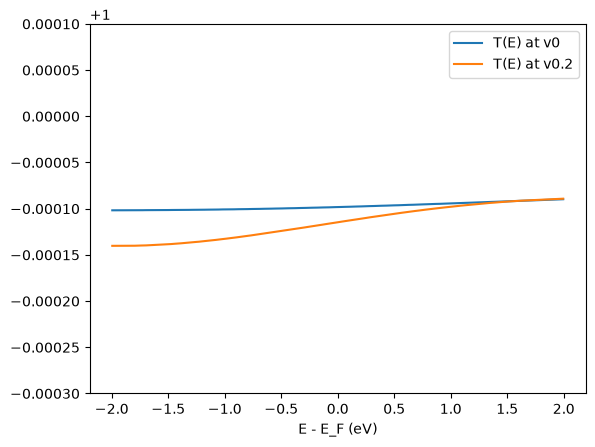

{
 "treatment": "self-consistent",
 "iv": {
  "frame": [
   null,
   null
  ],
  "voltages_v": [
   0.0,
   0.2
  ],
  "current_a": [
   0.0,
   1.54944e-05
  ],
  "current_a_printed": [
   0.0,
   7.7472e-06
  ],
  "computed": "tbtrans"
 }
}


In [12]:
# the transmission each point wrote, and the record
for v in ("v0", "v0.2"):
    t = sisl.get_sile(B / f"05_transmission/run-0/{v}/T.TBT.nc")
    E, Tr = t.E, t.transmission()
    print(v, len(E), "energies", E[0].round(4), "...", E[-1].round(4), "eV; T between", Tr.min().round(5), "and", Tr.max().round(5))
    plt.plot(E, Tr, label=f"T(E) at {v}")
plt.ylim(0.9997, 1.0001); plt.xlabel("E - E_F (eV)"); plt.legend(); plt.show()
rec = json.loads((B / "T.transport.json").read_text())
print(json.dumps({k: rec[k] for k in rec if k in ("treatment", "iv")}, indent=1)[:1500])